~~~
Copyright 2025 Google LLC

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
You may obtain a copy of the License at

    https://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software
distributed under the License is distributed on an "AS IS" BASIS,
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and
limitations under the License.
~~~

# Quick start with Hugging Face

<table><tbody><tr>
  <td style="text-align: center">
    <a href="https://colab.research.google.com/github/google-health/medgemma/blob/main/notebooks/quick_start_with_hugging_face.ipynb">
      <img alt="Google Colab logo" src="https://www.tensorflow.org/images/colab_logo_32px.png" width="32px"><br> Run in Google Colab
    </a>
  </td>
  <td style="text-align: center">
    <a href="https://console.cloud.google.com/vertex-ai/colab/import/https:%2F%2Fraw.githubusercontent.com%2FGoogle-Health%2Fmedgemma%2Fmain%2Fnotebooks%2Fquick_start_with_hugging_face.ipynb">
      <img alt="Google Cloud Colab Enterprise logo" src="https://lh3.googleusercontent.com/JmcxdQi-qOpctIvWKgPtrzZdJJK-J3sWE1RsfjZNwshCFgE_9fULcNpuXYTilIR2hjwN" width="32px"><br> Run in Colab Enterprise
    </a>
  </td>
  <td style="text-align: center">
    <a href="https://github.com/google-health/medgemma/blob/main/notebooks/quick_start_with_hugging_face.ipynb">
      <img alt="GitHub logo" src="https://github.githubassets.com/assets/GitHub-Mark-ea2971cee799.png" width="32px"><br> View on GitHub
    </a>
  </td>
  <td style="text-align: center">
    <a href="https://huggingface.co/collections/google/medgemma-release-680aade845f90bec6a3f60c4">
      <img alt="Hugging Face logo" src="https://huggingface.co/front/assets/huggingface_logo-noborder.svg" width="32px"><br> View on Hugging Face
    </a>
  </td>
</tr></tbody></table>

This notebook provides a basic demo of using MedGemma, a collection of Gemma 3 variants that are trained for performance on medical text and image comprehension. MedGemma is intended to accelerate building healthcare-based AI applications.

Learn more about the model at the [HAI-DEF developer site](https://developers.google.com/health-ai-developer-foundations/medgemma).

## Setup

To complete this tutorial, you'll need to have a runtime with [sufficient resources](https://ai.google.dev/gemma/docs/core#sizes) to run the MedGemma model.

You can try out MedGemma 4B for free in Google Colab using a T4 GPU:

1. In the upper-right of the Colab window, select **▾ (Additional connection options)**.
2. Select **Change runtime type**.
3. Under **Hardware accelerator**, select **T4 GPU**.

**Note**: To run the demo with MedGemma 27B in Google Colab, you will need a runtime with an A100 GPU.

### Get access to MedGemma

Before you get started, make sure that you have access to MedGemma models on Hugging Face:

1. If you don't already have a Hugging Face account, you can create one for free by clicking [here](https://huggingface.co/join).
2. Head over to the [MedGemma model page](https://huggingface.co/google/medgemma-1.5-4b-it) and accept the usage conditions.

### Authenticate with Hugging Face

Generate a Hugging Face `read` access token by going to [settings](https://huggingface.co/settings/tokens).

If you are using Google Colab, add your access token to the Colab Secrets manager to securely store it. If not, proceed to run the cell below to authenticate with Hugging Face.

1. Open your Google Colab notebook and click on the 🔑 Secrets tab in the left panel. <img src="https://storage.googleapis.com/generativeai-downloads/images/secrets.jpg" alt="The Secrets tab is found on the left panel." width=50%>
2. Create a new secret with the name `HF_TOKEN`.
3. Copy/paste your token key into the Value input box of `HF_TOKEN`.
4. Toggle the button on the left to allow notebook access to the secret.

In [1]:
import os
import sys

google_colab = "google.colab" in sys.modules and not os.environ.get("VERTEX_PRODUCT")

if google_colab:
    # Use secret if running in Google Colab
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
else:
    # Store Hugging Face data under `/content` if running in Colab Enterprise
    if os.environ.get("VERTEX_PRODUCT") == "COLAB_ENTERPRISE":
        os.environ["HF_HOME"] = "/content/hf"
    # Authenticate with Hugging Face
    from huggingface_hub import get_token
    if get_token() is None:
        from huggingface_hub import notebook_login
        notebook_login()

In [8]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [9]:
import importlib.metadata as md
import torch

for package in ["transformers", "accelerate", "huggingface_hub", "bitsandbytes"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: Not installed")

print("GPU capability:", torch.cuda.get_device_capability(0))
print("BF16 supported:", torch.cuda.is_bf16_supported())

transformers: 5.23.0
accelerate: 1.16.0
huggingface_hub: 1.33.0
bitsandbytes: 0.50.2
GPU capability: (7, 5)
BF16 supported: True


In [10]:
%pip install -q datasets evaluate scikit-learn pandas matplotlib seaborn pillow timm

In [11]:
import torch
import transformers
import accelerate
import datasets
import evaluate
import sklearn
import pandas
import timm

print("All libraries imported successfully!")
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Datasets:", datasets.__version__)
print("GPU:", torch.cuda.get_device_name(0))

All libraries imported successfully!
Transformers: 5.23.0
Accelerate: 1.16.0
Datasets: 4.8.5
GPU: Tesla T4


In [12]:
import pandas as pd

url = "https://huggingface.co/datasets/jason1966/alexteboul_diabetes-health-indicators-dataset/resolve/main/diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (253680, 22)

Columns:
['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

First 5 rows:


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [13]:
import pandas as pd
import numpy as np

print("DATASET QUALITY REPORT")
print("=" * 40)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nTarget class percentages:")
print(
    df["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nNumeric summary:")
display(df.describe().T)

print("\nInvalid target values:")
print(df[~df["Diabetes_012"].isin([0, 1, 2])].shape[0])

DATASET QUALITY REPORT

Missing values:
0

Duplicate rows:
23899

Data types:
float64    22
Name: count, dtype: int64

Target class percentages:
Diabetes_012
0.0    84.24
1.0     1.83
2.0    13.93
Name: proportion, dtype: float64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0



Invalid target values:
0


In [14]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"].astype(int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING DATA:", X_train.shape)
print("TESTING DATA:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))

TRAINING DATA: (202944, 21)
TESTING DATA: (50736, 21)

Training class distribution:
Diabetes_012
0    84.24
1     1.83
2    13.93
Name: proportion, dtype: float64

Testing class distribution:
Diabetes_012
0    84.24
1     1.83
2    13.93
Name: proportion, dtype: float64


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Create model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training Random Forest...")

rf_model.fit(X_train, y_train)

print("Training completed!")

# Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

Training Random Forest...
Training completed!

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.93      0.79      0.86     42741
 Prediabetes       0.02      0.01      0.01       926
    Diabetes       0.35      0.68      0.46      7069

    accuracy                           0.76     50736
   macro avg       0.43      0.49      0.44     50736
weighted avg       0.83      0.76      0.78     50736

Balanced Accuracy: 0.4934

CONFUSION MATRIX
[[33899   283  8559]
 [  422     7   497]
 [ 2198    67  4804]]


In [16]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [17]:
import numpy as np
import xgboost as xgb

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Calculate sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Create XGBoost model
xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    verbose=False
)

print("Training completed!")

# Predictions
xgb_pred = xgb_model.predict(X_test)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    xgb_pred,
    labels=[0, 1, 2],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, xgb_pred), 4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, xgb_pred))

Training XGBoost...
Training completed!

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.95      0.64      0.77     42741
 Prediabetes       0.03      0.30      0.06       926
    Diabetes       0.34      0.63      0.44      7069

    accuracy                           0.63     50736
   macro avg       0.44      0.52      0.42     50736
weighted avg       0.85      0.63      0.71     50736

Balanced Accuracy: 0.5228

CONFUSION MATRIX
[[27430  7231  8080]
 [  238   279   409]
 [ 1086  1563  4420]]


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report
import xgboost as xgb

# Split existing training data again
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Calculate class weights using fitting data only
fit_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_fit
)

# Train a validation model
validation_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print("Training validation model...")

validation_model.fit(
    X_fit,
    y_fit,
    sample_weight=fit_weights,
    verbose=False
)

# Evaluate on validation data
val_pred = validation_model.predict(X_val)

print("\nVALIDATION RESULTS")
print(classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

Training validation model...

VALIDATION RESULTS
              precision    recall  f1-score   support

 No Diabetes       0.96      0.64      0.77     34193
 Prediabetes       0.03      0.29      0.06       741
    Diabetes       0.34      0.63      0.44      5655

    accuracy                           0.64     40589
   macro avg       0.44      0.52      0.42     40589
weighted avg       0.85      0.64      0.71     40589



In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get predicted probabilities for prediabetes
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

actual_prediabetes = (y_val == 1).astype(int)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25,
              0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    predicted_prediabetes = (
        val_probabilities >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            actual_prediabetes,
            predicted_prediabetes,
            zero_division=0
        ),
        "Recall": recall_score(
            actual_prediabetes,
            predicted_prediabetes,
            zero_division=0
        ),
        "F1 Score": f1_score(
            actual_prediabetes,
            predicted_prediabetes,
            zero_division=0
        ),
        "Predicted Cases": predicted_prediabetes.sum()
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.round(3)
)

,Threshold,Precision,Recall,F1 Score,Predicted Cases
0,0.05,0.020,0.991,0.038,37529
1,0.10,0.021,0.964,0.041,34038
2,0.15,0.023,0.934,0.044,30694
3,0.20,0.024,0.891,0.047,27103
4,0.25,0.026,0.798,0.050,23061
5,0.30,0.028,0.690,0.054,18047
6,0.35,0.030,0.476,0.056,11845
7,0.40,0.033,0.267,0.058,6041
8,0.45,0.034,0.111,0.052,2402
9,0.50,0.038,0.045,0.041,875


In [20]:
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

# Group identical input profiles together
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

# Fresh 80/20 train-test split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Separate training and validation data
validation_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

fit_idx, val_idx = next(
    validation_splitter.split(
        X_train,
        y_train,
        groups[train_idx]
    )
)

X_fit = X_train.iloc[fit_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_fit = y_train.iloc[fit_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining class distribution:")
print(y_fit.value_counts(normalize=True).sort_index().round(3))

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

print("\nIdentical-profile overlap:")
print("Train/validation:", len(set(groups[train_idx][fit_idx]) & set(groups[train_idx][val_idx])))
print("Train/test:", len(set(groups[train_idx]) & set(groups[test_idx])))

Training: (162404, 21)
Validation: (40530, 21)
Testing: (50746, 21)

Training class distribution:
Diabetes_012
0    0.841
1    0.019
2    0.140
Name: proportion, dtype: float64

Validation class distribution:
Diabetes_012
0    0.844
1    0.018
2    0.138
Name: proportion, dtype: float64

Testing class distribution:
Diabetes_012
0    0.845
1    0.017
2    0.138
Name: proportion, dtype: float64

Identical-profile overlap:
Train/validation: 0
Train/test: 0


In [21]:
import importlib.util

libraries = ["sklearn", "xgboost", "lightgbm", "imblearn"]

for library in libraries:
    print(
        library,
        "Installed" if importlib.util.find_spec(library)
        else "Not installed"
    )

sklearn Installed
xgboost Installed
lightgbm Installed
imblearn Installed


In [22]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Handle class imbalance using training class weights
class_counts = y_fit.value_counts().sort_index()

class_weights = {
    cls: len(y_fit) / (len(class_counts) * count)
    for cls, count in class_counts.items()
}

sample_weights = y_fit.map(class_weights).to_numpy()

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        max_depth=10,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    print("\nTraining:", name)

    if name == "XGBoost":
        model.fit(
            X_fit, y_fit,
            sample_weight=sample_weights
        )
    else:
        model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)

    precision = precision_score(
        y_val, predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    recall = recall_score(
        y_val, predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    f1 = f1_score(
        y_val, predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Prediabetes Precision": precision[1],
        "Prediabetes Recall": recall[1],
        "Prediabetes F1": f1[1],
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )
    })

    print("\nClassification Report:")
    print(classification_report(
        y_val, predictions,
        labels=[0, 1, 2],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_val, predictions,
        labels=[0, 1, 2]
    ))

results_df = pd.DataFrame(results)

print("\n===== MODEL COMPARISON =====")
print(results_df.round(4).to_string(index=False))



Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.79      0.86     34216
           1       0.04      0.01      0.02       738
           2       0.35      0.69      0.46      5576

    accuracy                           0.76     40530
   macro avg       0.44      0.50      0.44     40530
weighted avg       0.83      0.76      0.79     40530

Confusion Matrix:
[[27101   171  6944]
 [  350     8   380]
 [ 1670    41  3865]]

Training: XGBoost

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.66      0.78     34216
           1       0.03      0.22      0.05       738
           2       0.33      0.66      0.44      5576

    accuracy                           0.65     40530
   macro avg       0.44      0.51      0.42     40530
weighted avg       0.85      0.65      0.72     40530

Confusion Matrix:
[[22440  4751  7025]
 [  210   161   367]
 [  

In [23]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50
]

threshold_results = []

for model_name in ["XGBoost", "LightGBM"]:

    model = models[model_name]

    probabilities = model.predict_proba(X_val)

    # Locate probability columns using actual class labels
    class_1_index = list(model.classes_).index(1)
    class_0_index = list(model.classes_).index(0)
    class_2_index = list(model.classes_).index(2)

    p1 = probabilities[:, class_1_index]
    p0 = probabilities[:, class_0_index]
    p2 = probabilities[:, class_2_index]

    for threshold in thresholds:

        # Predict prediabetes when its probability
        # reaches the selected threshold.
        predictions = np.where(
            p1 >= threshold,
            1,
            np.where(p0 >= p2, 0, 2)
        )

        precision = precision_score(
            y_val, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y_val, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        )

        f1 = f1_score(
            y_val, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        )

        cm = confusion_matrix(
            y_val, predictions,
            labels=[0, 1, 2]
        )

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Predicted Cases": int((predictions == 1).sum()),
            "True Positives": int(cm[1, 1]),
            "False Positives": int(cm[0, 1] + cm[2, 1]),
            "False Negatives": int(cm[1, 0] + cm[1, 2])
        })

threshold_df = pd.DataFrame(threshold_results)

print("===== THRESHOLD COMPARISON =====")
print(threshold_df.round(4).to_string(index=False))

print("\n===== BEST THRESHOLD BY PREDIABETES F1 =====")

best_results = (
    threshold_df
    .sort_values("F1 Score", ascending=False)
    .groupby("Model")
    .head(1)
)

print(best_results.round(4).to_string(index=False))


===== THRESHOLD COMPARISON =====
   Model  Threshold  Precision  Recall  F1 Score  Predicted Cases  True Positives  False Positives  False Negatives
 XGBoost       0.05     0.0196  0.9905    0.0385            37273             731            36542                7
 XGBoost       0.10     0.0212  0.9688    0.0416            33664             715            32949               23
 XGBoost       0.15     0.0226  0.9173    0.0441            29987             677            29310               61
 XGBoost       0.20     0.0238  0.8442    0.0462            26220             623            25597              115
 XGBoost       0.25     0.0258  0.7602    0.0499            21729             561            21168              177
 XGBoost       0.30     0.0281  0.6260    0.0537            16453             462            15991              276
 XGBoost       0.35     0.0280  0.3889    0.0522            10265             287             9978              451
 XGBoost       0.40     0.0298  0.2046 

===== FEATURE IMPORTANCE =====
             Feature  XGBoost  LightGBM   Average
                 BMI   0.0402      5261 2630.5201
                 Age   0.0472      3647 1823.5236
              Income   0.0323      2414 1207.0161
            MentHlth   0.0278      2316 1158.0139
            PhysHlth   0.0296      2303 1151.5148
             GenHlth   0.1197      1976  988.0598
           Education   0.0274      1659  829.5137
                 Sex   0.0276       782  391.0138
            HighChol   0.0811       753  376.5406
              HighBP   0.2398       629  314.6199
              Fruits   0.0247       626  313.0124
        PhysActivity   0.0266       603  301.5133
              Smoker   0.0258       596  298.0129
             Veggies   0.0256       583  291.5128
HeartDiseaseorAttack   0.0360       497  248.5180
            DiffWalk   0.0323       495  247.5162
   HvyAlcoholConsump   0.0356       424  212.0178
         NoDocbcCost   0.0314       414  207.0157
           CholChec

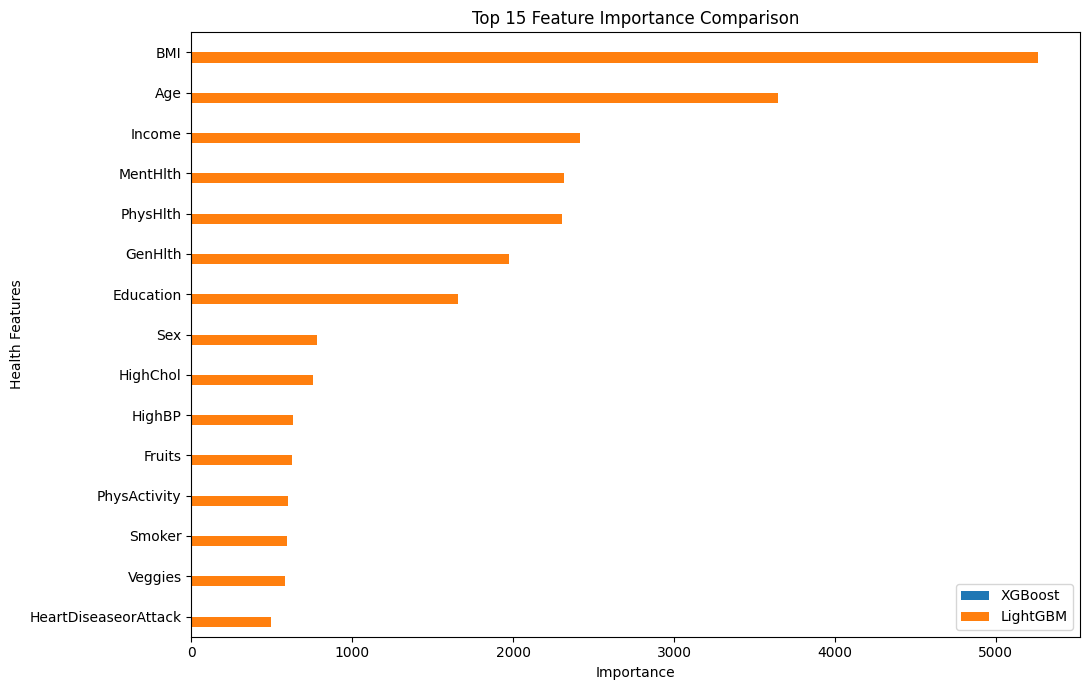

In [24]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance_data = pd.DataFrame({
    "Feature": X_fit.columns,
    "XGBoost": models["XGBoost"].feature_importances_,
    "LightGBM": models["LightGBM"].feature_importances_
})

# Sort by average importance
importance_data["Average"] = (
    importance_data["XGBoost"] +
    importance_data["LightGBM"]
) / 2

importance_data = importance_data.sort_values(
    "Average", ascending=False
)

print("===== FEATURE IMPORTANCE =====")
print(importance_data.round(4).to_string(index=False))

# Visualize top 15 features
top_features = importance_data.head(15)

top_features.set_index("Feature")[
    ["XGBoost", "LightGBM"]
].plot(
    kind="barh",
    figsize=(11, 7)
)

plt.title("Top 15 Feature Importance Comparison")
plt.xlabel("Importance")
plt.ylabel("Health Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


===== CORRECTED FEATURE IMPORTANCE =====
             Feature  XGBoost  LightGBM_Gain  Average
              HighBP   0.2398         0.1538   0.1968
             GenHlth   0.1197         0.2080   0.1639
                 BMI   0.0402         0.1528   0.0965
                 Age   0.0472         0.1247   0.0859
            HighChol   0.0811         0.0504   0.0658
              Income   0.0323         0.0558   0.0440
            MentHlth   0.0278         0.0447   0.0363
            PhysHlth   0.0296         0.0419   0.0358
           Education   0.0274         0.0329   0.0301
HeartDiseaseorAttack   0.0360         0.0146   0.0253
           CholCheck   0.0363         0.0120   0.0242
   HvyAlcoholConsump   0.0356         0.0120   0.0238
            DiffWalk   0.0323         0.0122   0.0222
                 Sex   0.0276         0.0163   0.0220
         NoDocbcCost   0.0314         0.0108   0.0211
        PhysActivity   0.0266         0.0110   0.0188
              Stroke   0.0291         0.0

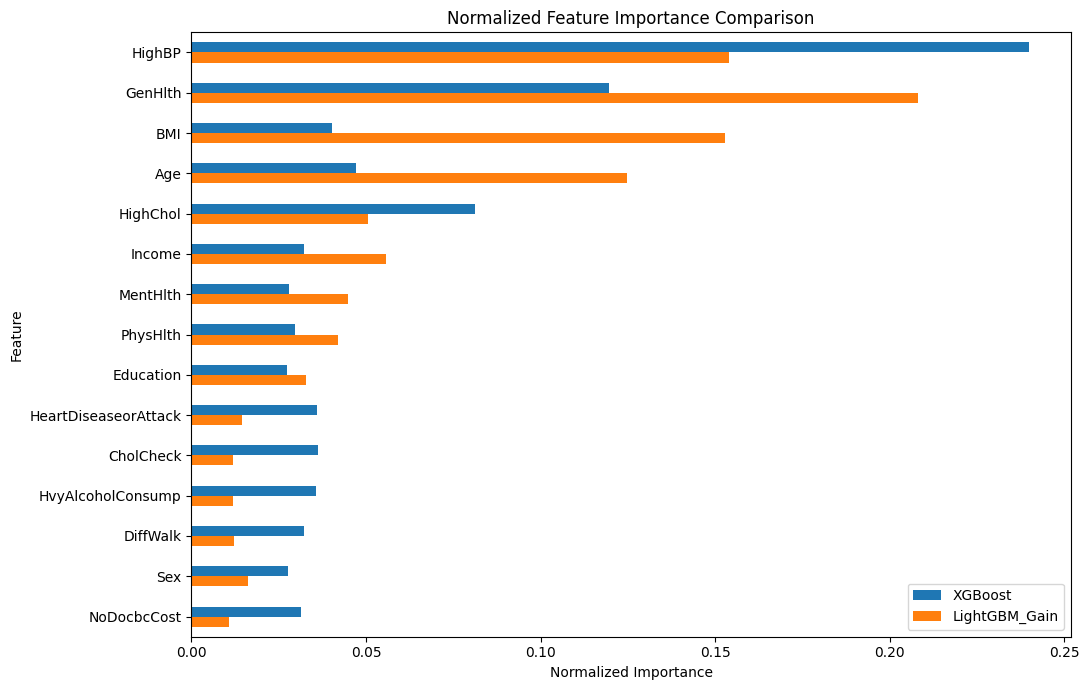

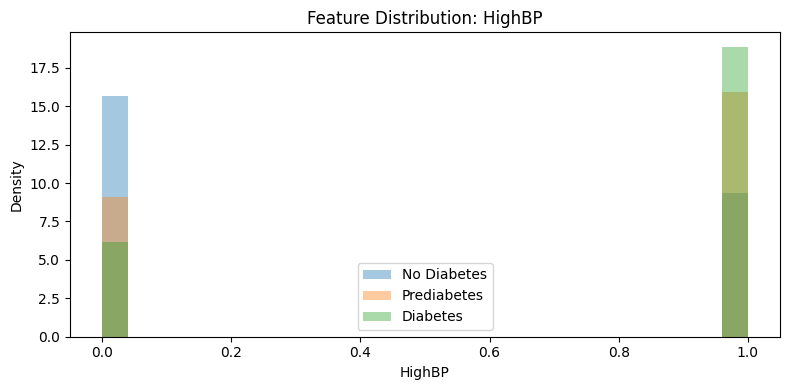

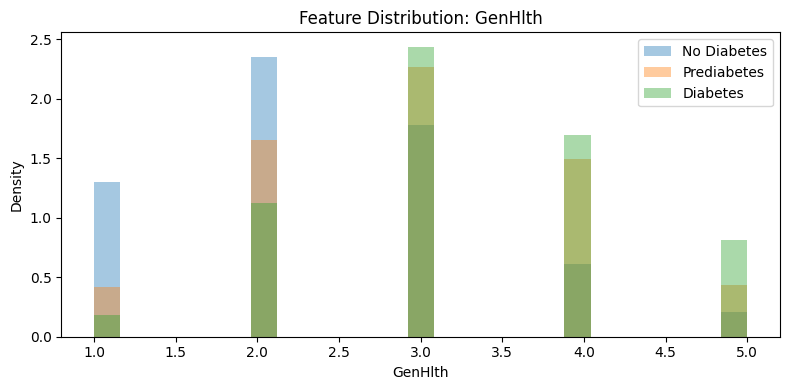

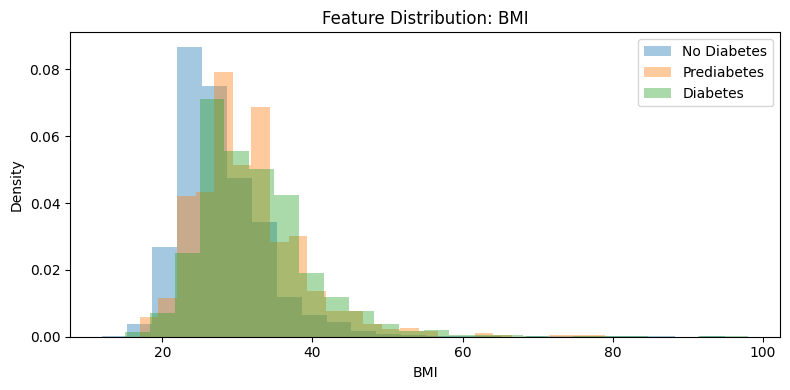

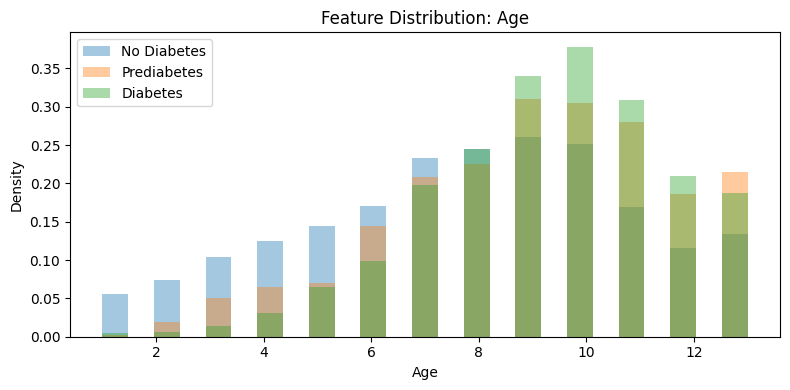

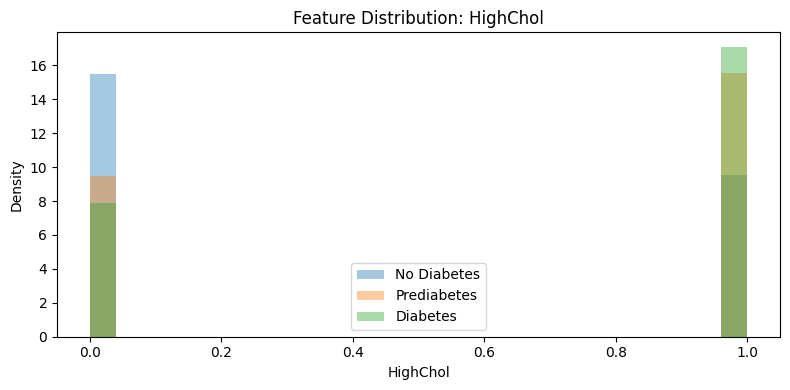

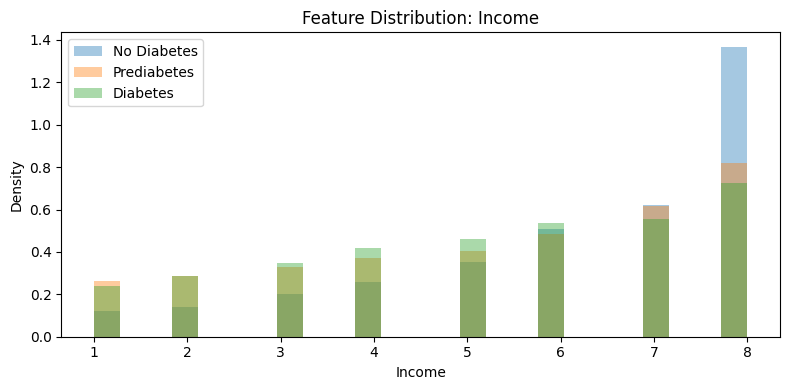

In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# XGBoost normalized importance
xgb_importance = models["XGBoost"].feature_importances_

# LightGBM gain-based importance
lgb_importance = models["LightGBM"].booster_.feature_importance(
    importance_type="gain"
)

# Normalize LightGBM importance
lgb_importance = lgb_importance / lgb_importance.sum()

# Create comparable importance table
importance_data = pd.DataFrame({
    "Feature": X_fit.columns,
    "XGBoost": xgb_importance,
    "LightGBM_Gain": lgb_importance
})

importance_data["Average"] = (
    importance_data["XGBoost"] +
    importance_data["LightGBM_Gain"]
) / 2

importance_data = importance_data.sort_values(
    "Average", ascending=False
)

print("===== CORRECTED FEATURE IMPORTANCE =====")
print(importance_data.round(4).to_string(index=False))

# Plot comparison
importance_data.head(15).set_index("Feature")[
    ["XGBoost", "LightGBM_Gain"]
].plot(
    kind="barh",
    figsize=(11, 7)
)

plt.title("Normalized Feature Importance Comparison")
plt.xlabel("Normalized Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Select top 6 features
selected_features = importance_data.head(6)["Feature"].tolist()

# Compare feature distributions across classes
analysis_df = X_val[selected_features].copy()
analysis_df["Target"] = y_val.values

for feature in selected_features:

    plt.figure(figsize=(8, 4))

    for class_id, class_name in [
        (0, "No Diabetes"),
        (1, "Prediabetes"),
        (2, "Diabetes")
    ]:

        values = analysis_df.loc[
            analysis_df["Target"] == class_id,
            feature
        ]

        plt.hist(
            values,
            bins=25,
            alpha=0.4,
            density=True,
            label=class_name
        )

    plt.title(f"Feature Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()



Feature: HighBP
         mean  median    std
Target                      
0       0.373     0.0  0.484
1       0.637     1.0  0.481
2       0.754     1.0  0.430


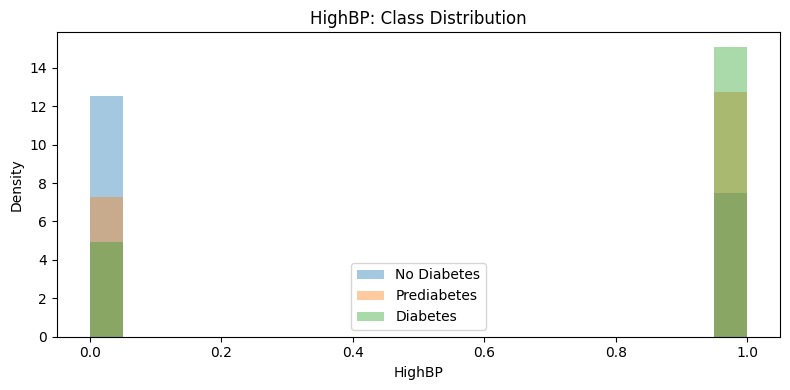


Feature: GenHlth
         mean  median    std
Target                      
0       2.372     2.0  1.023
1       2.980     3.0  1.023
2       3.293     3.0  1.001


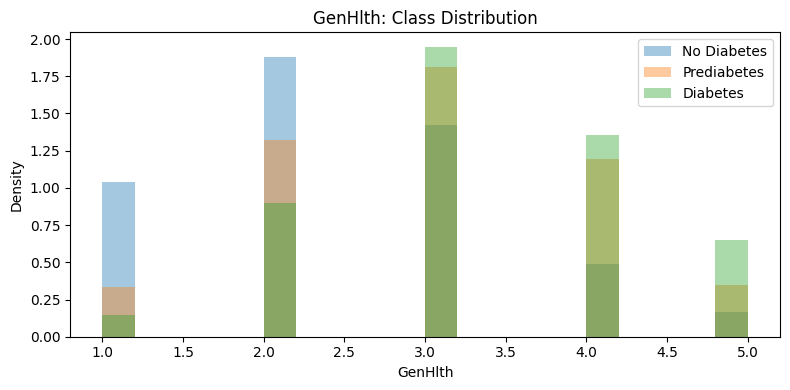


Feature: BMI
          mean  median    std
Target                       
0       27.754    27.0  6.351
1       31.237    30.0  7.438
2       32.182    31.0  7.715


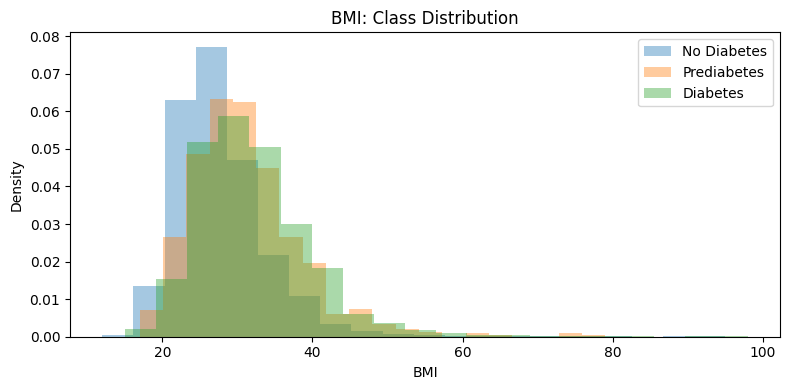


Feature: Age
         mean  median    std
Target                      
0       7.782     8.0  3.105
1       9.064     9.0  2.650
2       9.413    10.0  2.293


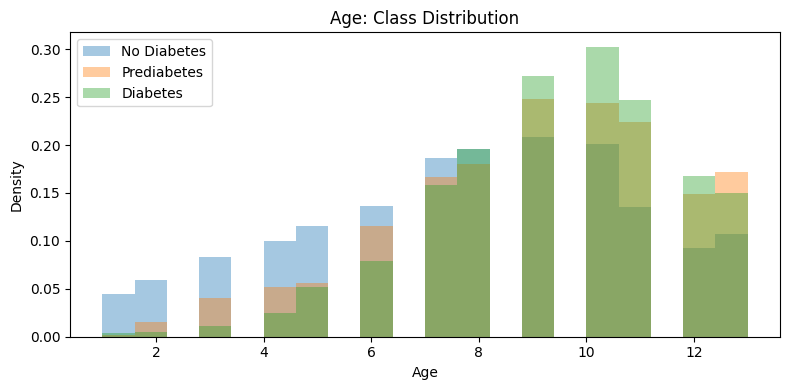


Feature: HighChol
         mean  median    std
Target                      
0       0.381     0.0  0.486
1       0.622     1.0  0.485
2       0.684     1.0  0.465


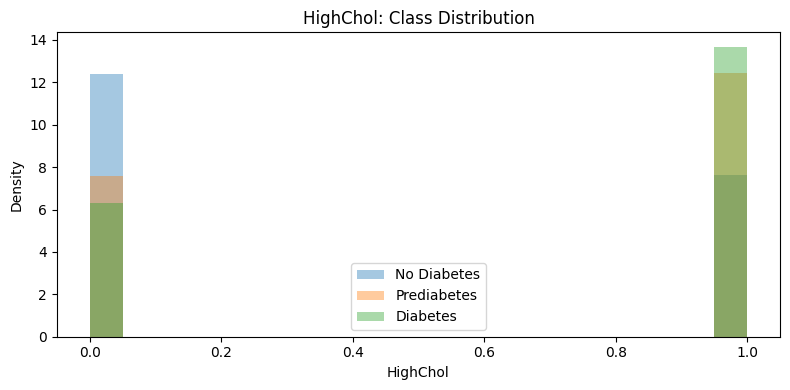

In [26]:

import matplotlib.pyplot as plt
import pandas as pd

top5 = [
    "HighBP",
    "GenHlth",
    "BMI",
    "Age",
    "HighChol"
]

comparison = X_val[top5].copy()
comparison["Target"] = y_val.values

for feature in top5:

    print("\nFeature:", feature)

    print(
        comparison.groupby("Target")[feature]
        .agg(["mean", "median", "std"])
        .round(3)
    )

    plt.figure(figsize=(8, 4))

    for class_id, label in [
        (0, "No Diabetes"),
        (1, "Prediabetes"),
        (2, "Diabetes")
    ]:

        values = comparison.loc[
            comparison["Target"] == class_id,
            feature
        ]

        plt.hist(
            values,
            bins=20,
            density=True,
            alpha=0.4,
            label=label
        )

    plt.title(f"{feature}: Class Distribution")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [27]:

import numpy as np
import pandas as pd

features = [
    "HighBP",
    "GenHlth",
    "BMI",
    "Age",
    "HighChol"
]

comparison = X_val[features].copy()
comparison["Target"] = y_val.values

results = []

for feature in features:

    normal = comparison.loc[
        comparison["Target"] == 0, feature
    ]

    prediabetes = comparison.loc[
        comparison["Target"] == 1, feature
    ]

    diabetes = comparison.loc[
        comparison["Target"] == 2, feature
    ]

    def standardized_difference(a, b):
        pooled_std = np.sqrt(
            (a.std() ** 2 + b.std() ** 2) / 2
        )

        if pooled_std == 0:
            return 0

        return (a.mean() - b.mean()) / pooled_std

    results.append({
        "Feature": feature,
        "Prediabetes_vs_Normal": standardized_difference(
            prediabetes, normal
        ),
        "Prediabetes_vs_Diabetes": standardized_difference(
            prediabetes, diabetes
        )
    })

separation_df = pd.DataFrame(results)

print("===== PREDIABETES FEATURE SEPARATION =====")
print(separation_df.round(4).to_string(index=False))


===== PREDIABETES FEATURE SEPARATION =====
 Feature  Prediabetes_vs_Normal  Prediabetes_vs_Diabetes
  HighBP                 0.5463                  -0.2576
 GenHlth                 0.5941                  -0.3091
     BMI                 0.5036                  -0.1247
     Age                 0.4439                  -0.1410
HighChol                 0.4957                  -0.1302


In [28]:

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import pandas as pd
import numpy as np

# Convert three classes into binary labels
y_fit_binary = (y_fit == 1).astype(int)
y_val_binary = (y_val == 1).astype(int)

# Calculate imbalance ratio using training data only
negative_count = (y_fit_binary == 0).sum()
positive_count = (y_fit_binary == 1).sum()

scale_weight = negative_count / positive_count

print("Positive training cases:", positive_count)
print("Negative training cases:", negative_count)
print("Scale positive weight:", round(scale_weight, 2))

# Define binary models
binary_models = {
    "XGBoost Binary": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_weight,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM Binary": LGBMClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

binary_results = []
binary_probabilities = {}

for name, model in binary_models.items():

    print("\nTraining:", name)

    model.fit(X_fit, y_fit_binary)

    probabilities = model.predict_proba(X_val)[:, 1]

    binary_probabilities[name] = probabilities

    predictions = (probabilities >= 0.5).astype(int)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val_binary, predictions))

    print("\nClassification Report:")
    from sklearn.metrics import classification_report

    print(classification_report(
        y_val_binary,
        predictions,
        zero_division=0
    ))

    binary_results.append({
        "Model": name,
        "PR_AUC": average_precision_score(
            y_val_binary, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_val_binary, probabilities
        ),
        "Precision": precision_score(
            y_val_binary, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_binary, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_val_binary, predictions,
            zero_division=0
        )
    })

binary_results_df = pd.DataFrame(binary_results)

print("\n===== BINARY MODEL COMPARISON =====")
print(binary_results_df.round(4).to_string(index=False))


Positive training cases: 3037
Negative training cases: 159367
Scale positive weight: 52.48

Training: XGBoost Binary

Confusion Matrix:
[[23750 16042]
 [  219   519]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.60      0.74     39792
           1       0.03      0.70      0.06       738

    accuracy                           0.60     40530
   macro avg       0.51      0.65      0.40     40530
weighted avg       0.97      0.60      0.73     40530


Training: LightGBM Binary

Confusion Matrix:
[[25314 14478]
 [  274   464]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.64      0.77     39792
           1       0.03      0.63      0.06       738

    accuracy                           0.64     40530
   macro avg       0.51      0.63      0.42     40530
weighted avg       0.97      0.64      0.76     40530


===== BINARY MODEL COMPARISON =====
          Model  

In [29]:
threshold_results = []

for model_name, probabilities in binary_probabilities.items():

    for threshold in [
        0.05, 0.10, 0.15, 0.20, 0.25,
        0.30, 0.35, 0.40, 0.45, 0.50
    ]:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        cm = confusion_matrix(
            y_val_binary,
            predictions,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val_binary, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val_binary, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_val_binary, predictions,
                zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

binary_threshold_df = pd.DataFrame(threshold_results)

print("===== BINARY THRESHOLD COMPARISON =====")
print(binary_threshold_df.round(4).to_string(index=False))

print("\n===== BEST BINARY F1 =====")

print(
    binary_threshold_df.sort_values(
        "F1", ascending=False
    ).groupby("Model").head(1).to_string(index=False)
)

===== BINARY THRESHOLD COMPARISON =====
          Model  Threshold  Precision  Recall     F1  TP    FP  FN
 XGBoost Binary       0.05     0.0188  0.9973 0.0369 736 38413   2
 XGBoost Binary       0.10     0.0200  0.9864 0.0392 728 35709  10
 XGBoost Binary       0.15     0.0213  0.9810 0.0417 724 33300  14
 XGBoost Binary       0.20     0.0224  0.9580 0.0438 707 30860  31
 XGBoost Binary       0.25     0.0237  0.9444 0.0462 697 28748  41
 XGBoost Binary       0.30     0.0249  0.9173 0.0486 677 26472  61
 XGBoost Binary       0.35     0.0261  0.8767 0.0506 647 24175  91
 XGBoost Binary       0.40     0.0276  0.8360 0.0535 617 21718 121
 XGBoost Binary       0.45     0.0291  0.7737 0.0562 571 19026 167
 XGBoost Binary       0.50     0.0313  0.7033 0.0600 519 16042 219
LightGBM Binary       0.05     0.0194  0.9932 0.0380 733 37104   5
LightGBM Binary       0.10     0.0206  0.9743 0.0403 719 34259  19
LightGBM Binary       0.15     0.0215  0.9499 0.0420 701 31915  37
LightGBM Binary       

In [30]:
score_analysis = pd.DataFrame({
    "Actual_Class": y_val.to_numpy(),
    "Predicted_Probability": binary_probabilities[
        "XGBoost Binary"
    ]
})

score_summary = (
    score_analysis
    .groupby("Actual_Class")["Predicted_Probability"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max"
    )
)

score_summary["25%"] = (
    score_analysis.groupby("Actual_Class")[
        "Predicted_Probability"
    ].quantile(0.25)
)

score_summary["75%"] = (
    score_analysis.groupby("Actual_Class")[
        "Predicted_Probability"
    ].quantile(0.75)
)

print("===== PREDICTED SCORE DISTRIBUTION =====")
print(score_summary.round(4))

===== PREDICTED SCORE DISTRIBUTION =====
              Count    Mean  Median     Min     Max     25%     75%
Actual_Class                                                       
0             34216  0.3773  0.3907  0.0045  0.8702  0.1938  0.5515
1               738  0.5498  0.5863  0.0254  0.8089  0.4729  0.6613
2              5576  0.5853  0.6135  0.0248  0.8748  0.5280  0.6731


In [31]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import pandas as pd

# Convert labels to NumPy arrays
y_fit_array = np.asarray(y_fit)
y_val_array = np.asarray(y_val)

comparisons = {
    "Prediabetes vs No Diabetes": (1, 0),
    "Prediabetes vs Diabetes": (1, 2)
}

pairwise_models = {}
pairwise_results = []

for name, (positive_class, negative_class) in comparisons.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    # Select only the two relevant classes
    fit_mask = np.isin(
        y_fit_array, [positive_class, negative_class]
    )

    val_mask = np.isin(
        y_val_array, [positive_class, negative_class]
    )

    X_pair_fit = X_fit.iloc[np.where(fit_mask)[0]]
    X_pair_val = X_val.iloc[np.where(val_mask)[0]]

    y_pair_fit = (
        y_fit_array[fit_mask] == positive_class
    ).astype(int)

    y_pair_val = (
        y_val_array[val_mask] == positive_class
    ).astype(int)

    # Calculate class imbalance from training data only
    positive_count = np.sum(y_pair_fit == 1)
    negative_count = np.sum(y_pair_fit == 0)

    weight = negative_count / positive_count

    print("Training positives:", positive_count)
    print("Training negatives:", negative_count)
    print("Positive weight:", round(weight, 2))
    print("Validation positives:", np.sum(y_pair_val == 1))
    print("Validation negatives:", np.sum(y_pair_val == 0))

    # Train XGBoost
    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=weight,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_pair_fit, y_pair_fit)

    probabilities = model.predict_proba(X_pair_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    pairwise_models[name] = {
        "model": model,
        "probabilities": probabilities,
        "y_true": y_pair_val
    }

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_pair_val, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_pair_val,
        predictions,
        zero_division=0
    ))

    pairwise_results.append({
        "Comparison": name,
        "PR_AUC": average_precision_score(
            y_pair_val, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_pair_val, probabilities
        )
    })

print("\n===== PAIRWISE MODEL COMPARISON =====")
print(
    pd.DataFrame(pairwise_results)
    .round(4)
    .to_string(index=False)
)


Prediabetes vs No Diabetes
Training positives: 3037
Training negatives: 136585
Positive weight: 44.97
Validation positives: 738
Validation negatives: 34216

Confusion Matrix:
[[22761 11455]
 [  214   524]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.67      0.80     34216
           1       0.04      0.71      0.08       738

    accuracy                           0.67     34954
   macro avg       0.52      0.69      0.44     34954
weighted avg       0.97      0.67      0.78     34954


Prediabetes vs Diabetes
Training positives: 3037
Training negatives: 22782
Positive weight: 7.5
Validation positives: 738
Validation negatives: 5576

Confusion Matrix:
[[3690 1886]
 [ 356  382]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.66      0.77      5576
           1       0.17      0.52      0.25       738

    accuracy                           0.64      6314
   m

In [32]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65,
    0.70, 0.75, 0.80, 0.85
]

pairwise_threshold_results = []

for name, result in pairwise_models.items():

    y_true = result["y_true"]
    probabilities = result["probabilities"]

    print(f"\n===== {name} =====")
    print(
        "PR-AUC baseline:",
        round(y_true.mean(), 4)
    )

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        ).ravel()

        pairwise_threshold_results.append({
            "Comparison": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_true, predictions,
                zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

pairwise_threshold_df = pd.DataFrame(
    pairwise_threshold_results
)

print("\n===== PAIRWISE THRESHOLD RESULTS =====")
print(
    pairwise_threshold_df.round(4).to_string(index=False)
)


===== Prediabetes vs No Diabetes =====
PR-AUC baseline: 0.0211

===== Prediabetes vs Diabetes =====
PR-AUC baseline: 0.1169

===== PAIRWISE THRESHOLD RESULTS =====
                Comparison  Threshold  Precision  Recall     F1  TP    FP  FN
Prediabetes vs No Diabetes       0.30     0.0324  0.9051 0.0626 668 19942  70
Prediabetes vs No Diabetes       0.35     0.0346  0.8699 0.0665 642 17927  96
Prediabetes vs No Diabetes       0.40     0.0372  0.8238 0.0712 608 15722 130
Prediabetes vs No Diabetes       0.45     0.0402  0.7737 0.0764 571 13639 167
Prediabetes vs No Diabetes       0.50     0.0437  0.7100 0.0824 524 11455 214
Prediabetes vs No Diabetes       0.55     0.0492  0.6491 0.0914 479  9266 259
Prediabetes vs No Diabetes       0.60     0.0536  0.5501 0.0977 406  7166 332
Prediabetes vs No Diabetes       0.65     0.0594  0.4363 0.1046 322  5099 416
Prediabetes vs No Diabetes       0.70     0.0679  0.3211 0.1121 237  3252 501
Prediabetes vs No Diabetes       0.75     0.0773  0.193

In [33]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

unweighted_models = {}
unweighted_results = []

for name, (positive_class, negative_class) in comparisons.items():

    print("\n" + "=" * 55)
    print(name, "- WITHOUT CLASS WEIGHTING")
    print("=" * 55)

    fit_mask = np.isin(
        y_fit_array, [positive_class, negative_class]
    )

    val_mask = np.isin(
        y_val_array, [positive_class, negative_class]
    )

    X_pair_fit = X_fit.iloc[np.where(fit_mask)[0]]
    X_pair_val = X_val.iloc[np.where(val_mask)[0]]

    y_pair_fit = (
        y_fit_array[fit_mask] == positive_class
    ).astype(int)

    y_pair_val = (
        y_val_array[val_mask] == positive_class
    ).astype(int)

    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_pair_fit, y_pair_fit)

    probabilities = model.predict_proba(X_pair_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    unweighted_models[name] = {
        "model": model,
        "probabilities": probabilities,
        "y_true": y_pair_val
    }

    print("Confusion Matrix:")
    print(confusion_matrix(y_pair_val, predictions))

    unweighted_results.append({
        "Comparison": name,
        "PR_AUC": average_precision_score(
            y_pair_val, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_pair_val, probabilities
        ),
        "Precision": precision_score(
            y_pair_val, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_pair_val, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_pair_val, predictions,
            zero_division=0
        )
    })

print("\n===== UNWEIGHTED MODEL RESULTS =====")
print(
    pd.DataFrame(unweighted_results)
    .round(4)
    .to_string(index=False)
)


Prediabetes vs No Diabetes - WITHOUT CLASS WEIGHTING
Confusion Matrix:
[[34216     0]
 [  738     0]]

Prediabetes vs Diabetes - WITHOUT CLASS WEIGHTING
Confusion Matrix:
[[5574    2]
 [ 736    2]]

===== UNWEIGHTED MODEL RESULTS =====
                Comparison  PR_AUC  ROC_AUC  Precision  Recall     F1
Prediabetes vs No Diabetes  0.0608   0.7583        0.0  0.0000 0.0000
   Prediabetes vs Diabetes  0.1894   0.6297        0.5  0.0027 0.0054


In [34]:
unweighted_threshold_results = []

thresholds = [
    0.01, 0.02, 0.03, 0.04, 0.05,
    0.06, 0.08, 0.10, 0.12, 0.15,
    0.20, 0.25, 0.30
]

for name, result in unweighted_models.items():

    y_true = result["y_true"]
    probabilities = result["probabilities"]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        ).ravel()

        unweighted_threshold_results.append({
            "Comparison": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_true, predictions,
                zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

unweighted_threshold_df = pd.DataFrame(
    unweighted_threshold_results
)

print("===== UNWEIGHTED THRESHOLD RESULTS =====")
print(
    unweighted_threshold_df.round(4).to_string(index=False)
)

===== UNWEIGHTED THRESHOLD RESULTS =====
                Comparison  Threshold  Precision  Recall     F1  TP    FP  FN
Prediabetes vs No Diabetes       0.01     0.0317  0.9079 0.0612 670 20489  68
Prediabetes vs No Diabetes       0.02     0.0410  0.7615 0.0779 562 13131 176
Prediabetes vs No Diabetes       0.03     0.0510  0.6192 0.0942 457  8509 281
Prediabetes vs No Diabetes       0.04     0.0585  0.4621 0.1039 341  5486 397
Prediabetes vs No Diabetes       0.05     0.0668  0.3388 0.1116 250  3494 488
Prediabetes vs No Diabetes       0.06     0.0742  0.2466 0.1141 182  2270 556
Prediabetes vs No Diabetes       0.08     0.0826  0.1152 0.0962  85   944 653
Prediabetes vs No Diabetes       0.10     0.1181  0.0637 0.0827  47   351 691
Prediabetes vs No Diabetes       0.12     0.1361  0.0312 0.0507  23   146 715
Prediabetes vs No Diabetes       0.15     0.0909  0.0041 0.0078   3    30 735
Prediabetes vs No Diabetes       0.20     0.0000  0.0000 0.0000   0     5 738
Prediabetes vs No Diabe

In [35]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

y_test_array = np.asarray(y_test)

final_thresholds = {
    "Prediabetes vs No Diabetes": 0.06,
    "Prediabetes vs Diabetes": 0.12
}

final_test_results = []

for name, threshold in final_thresholds.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    positive_class, negative_class = comparisons[name]

    test_mask = np.isin(
        y_test_array,
        [positive_class, negative_class]
    )

    X_pair_test = X_test.iloc[
        np.where(test_mask)[0]
    ]

    y_pair_test = (
        y_test_array[test_mask] == positive_class
    ).astype(int)

    # Use the already-trained unweighted model
    model = unweighted_models[name]["model"]

    probabilities = model.predict_proba(
        X_pair_test
    )[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    print("Locked threshold:", threshold)
    print("Test positive cases:", np.sum(y_pair_test == 1))
    print("Test negative cases:", np.sum(y_pair_test == 0))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_pair_test,
        predictions,
        labels=[0, 1]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_pair_test,
        predictions,
        zero_division=0
    ))

    final_test_results.append({
        "Comparison": name,
        "Threshold": threshold,
        "PR_AUC": average_precision_score(
            y_pair_test, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_pair_test, probabilities
        ),
        "Precision": precision_score(
            y_pair_test, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_pair_test, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_pair_test, predictions,
            zero_division=0
        )
    })

print("\n===== FINAL TEST RESULTS =====")
print(
    pd.DataFrame(final_test_results)
    .round(4)
    .to_string(index=False)
)


Prediabetes vs No Diabetes
Locked threshold: 0.06
Test positive cases: 856
Test negative cases: 42902

Confusion Matrix:
[[40144  2758]
 [  673   183]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96     42902
           1       0.06      0.21      0.10       856

    accuracy                           0.92     43758
   macro avg       0.52      0.57      0.53     43758
weighted avg       0.97      0.92      0.94     43758


Prediabetes vs Diabetes
Locked threshold: 0.12
Test positive cases: 856
Test negative cases: 6988

Confusion Matrix:
[[4491 2497]
 [ 387  469]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.64      0.76      6988
           1       0.16      0.55      0.25       856

    accuracy                           0.63      7844
   macro avg       0.54      0.60      0.50      7844
weighted avg       0.84      0.63      0.70      7844



In [36]:
try:
    import shap
    print("SHAP version:", shap.__version__)
    print("SHAP is ready!")
except ImportError:
    print("SHAP is not installed.")

SHAP version: 0.54.1
SHAP is ready!


### Install dependencies

In [2]:

import numpy as np
import shap
import matplotlib.pyplot as plt

# 1. Rebuild Model A validation data
y_val_array = np.asarray(y_val)

val_mask = np.isin(y_val_array, [1, 0])

X_shap_val = X_val.iloc[np.where(val_mask)[0]]
y_shap_val = (y_val_array[val_mask] == 1).astype(int)

# 2. Get the trained unweighted XGBoost model
model = unweighted_models["Prediabetes vs No Diabetes"]["model"]

# 3. Select 1,000 validation samples
X_shap_sample = X_shap_val.sample(
    n=min(1000, len(X_shap_val)),
    random_state=42
)

print("Validation samples:", len(X_shap_val))
print("SHAP samples:", len(X_shap_sample))
print("Features:", X_shap_sample.shape[1])

# 4. Calculate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap_sample)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP values shape:", shap_values.shape)

# 5. Global feature importance
print("\nSHAP Feature Importance")
shap.summary_plot(
    shap_values,
    X_shap_sample,
    plot_type="bar",
    show=True
)

# 6. Feature impact and direction
print("\nSHAP Feature Impact")
shap.summary_plot(
    shap_values,
    X_shap_sample,
    show=True
)


NameError: name 'y_val' is not defined

In [3]:

required_vars = [
    "X_val",
    "y_val",
    "X_fit",
    "y_fit",
    "X_test",
    "y_test",
    "unweighted_models",
    "df"
]

for name in required_vars:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")


X_val: NOT AVAILABLE
y_val: NOT AVAILABLE
X_fit: NOT AVAILABLE
y_fit: NOT AVAILABLE
X_test: NOT AVAILABLE
y_test: NOT AVAILABLE
unweighted_models: NOT AVAILABLE
df: NOT AVAILABLE


In [4]:

required_vars = [
    "X_val",
    "y_val",
    "X_fit",
    "y_fit",
    "X_test",
    "y_test",
    "unweighted_models",
    "df"
]

for name in required_vars:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")


X_val: NOT AVAILABLE
y_val: NOT AVAILABLE
X_fit: NOT AVAILABLE
y_fit: NOT AVAILABLE
X_test: NOT AVAILABLE
y_test: NOT AVAILABLE
unweighted_models: NOT AVAILABLE
df: NOT AVAILABLE


In [5]:
required_vars = [
    "X_val",
    "y_val",
    "X_fit",
    "y_fit",
    "X_test",
    "y_test",
    "unweighted_models",
    "df"
]

for name in required_vars:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

X_val: NOT AVAILABLE
y_val: NOT AVAILABLE
X_fit: NOT AVAILABLE
y_fit: NOT AVAILABLE
X_test: NOT AVAILABLE
y_test: NOT AVAILABLE
unweighted_models: NOT AVAILABLE
df: NOT AVAILABLE


In [6]:
import os

print("Current directory:", os.getcwd())

print("\nFiles in current directory:")
for file in os.listdir():
    print(file)

Current directory: /content

Files in current directory:
.config
sample_data


In [7]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [8]:
import os

drive_path = "/content/drive/MyDrive"

print("Google Drive folders and files:\n")

for root, dirs, files in os.walk(drive_path):
    level = root.replace(drive_path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

Google Drive folders and files:

MyDrive/
  PPT for conference 112247.pptx
  Document from 𝑆𝑎𝑟𝑚𝑖💝💫.pdf
  Sarmi Resume.pdf
  SARMILA J_20260101_140956_0000.pdf
  ABS.docx
  power4.pbix
  ASSIGN22.pbix
  power2.pbix
  ASSIGN.pbix
  powerbi.txt
  project1.pbix
  project22.pbix
  power44.pbix
  micro.txt
  assignmenT.pbix
  aB.docx
  s.docx
  12333.pbix
  power3.pbix
  ABBB.docx
  ASSIGN111.pbix
  project2.pbix
  power33.pbix
  project11.pbix
  assign1.pbix
  assignmenTT.pbix
  Day 2 bonus.docx
  Abstract.docx
  Screenshot_2026-03-24-19-06-35-91_6012fa4d4ddec268fc5c7112cbb265e7.jpg
  RESUME2026_20260728_091022_0000 (1).pdf
  RESUME2026_20260728_091022_0000.pdf
  ResumeSarmi (1).pdf
  ResumeSarmi.pdf
  ResumeCSE (1).pdf
  ResumeCSE.pdf
  Resume.Sarmi.pdf
  Resume2026CSE (1).pdf
  Resume2026CSE.pdf
  sarmi pic.png
  Diabetes Prediction Application.zip
  Classroom/
    CSE B 2022-23 B/
    Engineering graphics CSE B/
    Programming in C - I CSE B ( 2022 - 2023 even)/
      Assignment 2.pdf
 

In [10]:

import json
import os

folder = "/content/drive/MyDrive/Colab Notebooks"

notebooks = [
    "Diabetes Readmission Prediction.ipynb",
    "DiabetesPatientPrediction.ipynb"
]

for filename in notebooks:
    path = os.path.join(folder, filename)

    print("\n" + "=" * 65)
    print("NOTEBOOK:", filename)

    if not os.path.exists(path):
        print("File not found")
        continue

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])

            keywords = [
                "Diabetes_012",
                "diabetes_binary",
                "XGBoost",
                "readmission",
                "diabetes_Health_Indicators",
                "BRFSS"
            ]

            if any(word.lower() in source.lower() for word in keywords):
                print(f"\n--- Cell {i} ---")
                print(source[:1200])



NOTEBOOK: Diabetes Readmission Prediction.ipynb

--- Cell 25 ---
import joblib

joblib.dump(final_pipeline, 'diabetes_readmission_model.pkl')

--- Cell 26 ---
import joblib

joblib.dump(final_pipeline, 'diabetes_readmission_model.pkl')

--- Cell 27 ---
import os

print(os.path.exists('diabetes_readmission_model.pkl'))

--- Cell 28 ---
print(os.path.getsize('diabetes_readmission_model.pkl'), "bytes")

--- Cell 29 ---
import joblib

loaded_model = joblib.load('diabetes_readmission_model.pkl')

print("Model loaded successfully!")

--- Cell 31 ---
from google.colab import files

files.download('diabetes_readmission_model.pkl')

NOTEBOOK: DiabetesPatientPrediction.ipynb


In [11]:

import json
import os

path = "/content/drive/MyDrive/Colab Notebooks/DiabetesPatientPrediction.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if source.strip():
        print(f"\n{'='*50}")
        print(f"CELL {i} | {cell['cell_type']}")
        print(source[:700])


Total cells: 75

CELL 0 | code
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

CELL 1 | code
from google.colab import files
import pandas as pd

uploaded = files.upload()

CELL 2 | code
df = pd.read_csv("diabetes_prediction_india (1).csv")

print("Dataset shape:", df.shape)
df.head()

CELL 3 | code
df.info()

CELL 4 | code
print(df.columns.tolist())

CELL 5 | code
print(df.isnull().s

In [ ]:

import os

search_path = "/content/drive/MyDrive"

keywords = [
    "diabetes",
    "health_indicators",
    "BRFSS",
    "CDC",
    "xgboost",
    "model"
]

print("Searching for relevant files...\n")

for root, dirs, files in os.walk(search_path):
    dirs[:] = [
        d for d in dirs
        if d not in ["Classroom", ".trash"]
    ]

    for file in files:
        if any(word in file.lower() for word in keywords):
            print(os.path.join(root, file))


In [12]:

import os

search_path = "/content/drive/MyDrive"

keywords = [
    "diabetes",
    "health_indicators",
    "BRFSS",
    "CDC",
    "xgboost",
    "model"
]

print("Searching for relevant files...\n")

for root, dirs, files in os.walk(search_path):
    dirs[:] = [
        d for d in dirs
        if d not in ["Classroom", ".trash"]
    ]

    for file in files:
        if any(word in file.lower() for word in keywords):
            print(os.path.join(root, file))


Searching for relevant files...

/content/drive/MyDrive/Diabetes Prediction Application.zip
/content/drive/MyDrive/Colab Notebooks/Diabetes Readmission Prediction.ipynb
/content/drive/MyDrive/Colab Notebooks/DiabetesPatientPrediction.ipynb


In [13]:

import os

print("Kaggle folder exists:",
      os.path.exists("/root/.kaggle"))

print("Kaggle API token exists:",
      os.path.exists("/root/.kaggle/kaggle.json"))


Kaggle folder exists: False
Kaggle API token exists: False


In [14]:

import pandas as pd

url = "https://huggingface.co/datasets/jason1966/alexteboul_diabetes-health-indicators-dataset/resolve/main/diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())

print("\nFirst five rows:")
display(df.head())


Dataset downloaded successfully!
Dataset shape: (253680, 22)

Columns:
['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

First five rows:


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [15]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# 1. Separate features and target
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"].astype(int)

# 2. Create groups from identical feature profiles
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

# 3. First split: Train + Validation / Test
splitter_test = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter_test.split(X, y, groups)
)

X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups[train_val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# 4. Second split: Fit / Validation
splitter_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

fit_idx, val_idx = next(
    splitter_val.split(
        X_train_val,
        y_train_val,
        groups_train_val
    )
)

X_fit = X_train_val.iloc[fit_idx]
y_fit = y_train_val.iloc[fit_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

# 5. Display dataset sizes
print("DATA SPLIT RESULTS")
print("=" * 45)

print("X_fit:", X_fit.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nCLASS DISTRIBUTION")

for name, target in [
    ("Fit", y_fit),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts(normalize=True).sort_index().round(4))

# 6. Check group overlap
fit_groups = set(groups[train_val_idx][fit_idx])
val_groups = set(groups[train_val_idx][val_idx])
test_groups = set(groups[test_idx])

print("\nGROUP OVERLAP CHECK")
print("Fit vs Validation:", len(fit_groups & val_groups))
print("Fit vs Test:", len(fit_groups & test_groups))
print("Validation vs Test:", len(val_groups & test_groups))


DATA SPLIT RESULTS
X_fit: (162404, 21)
X_val: (40530, 21)
X_test: (50746, 21)

CLASS DISTRIBUTION

Fit:
Diabetes_012
0    0.8410
1    0.0187
2    0.1403
Name: proportion, dtype: float64

Validation:
Diabetes_012
0    0.8442
1    0.0182
2    0.1376
Name: proportion, dtype: float64

Test:
Diabetes_012
0    0.8454
1    0.0169
2    0.1377
Name: proportion, dtype: float64

GROUP OVERLAP CHECK
Fit vs Validation: 0
Fit vs Test: 0
Validation vs Test: 0


In [16]:

from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
import numpy as np

unweighted_models = {}

comparisons = {
    "Prediabetes vs No Diabetes": [0, 1],
    "Prediabetes vs Diabetes": [1, 2]
}

for name, classes in comparisons.items():

    print("\nTraining:", name)

    # Filter training data
    train_mask = y_fit.isin(classes)

    X_pair_fit = X_fit.loc[train_mask]
    y_pair_fit = (y_fit.loc[train_mask] == 1).astype(int)

    # Filter validation data
    val_mask = y_val.isin(classes)

    X_pair_val = X_val.loc[val_mask]
    y_pair_val = (y_val.loc[val_mask] == 1).astype(int)

    # Train unweighted XGBoost
    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_pair_fit, y_pair_fit)

    probabilities = model.predict_proba(X_pair_val)[:, 1]

    # Save model and validation results
    unweighted_models[name] = {
        "model": model,
        "probabilities": probabilities,
        "y_true": y_pair_val
    }

    print("Training samples:", len(X_pair_fit))
    print("Validation samples:", len(X_pair_val))
    print("PR-AUC:", round(
        average_precision_score(y_pair_val, probabilities), 4
    ))
    print("ROC-AUC:", round(
        roc_auc_score(y_pair_val, probabilities), 4
    ))

print("\nBoth unweighted models restored successfully!")



Training: Prediabetes vs No Diabetes
Training samples: 139622
Validation samples: 34954
PR-AUC: 0.0562
ROC-AUC: 0.7491

Training: Prediabetes vs Diabetes
Training samples: 25819
Validation samples: 6314
PR-AUC: 0.1768
ROC-AUC: 0.6127

Both unweighted models restored successfully!


Models saved: /content/drive/MyDrive/DiabeGuard_AI_Models/unweighted_pairwise_xgboost_models.joblib

SHAP validation samples: 1000
Number of features: 21
SHAP values shape: (1000, 21)

GLOBAL FEATURE IMPORTANCE


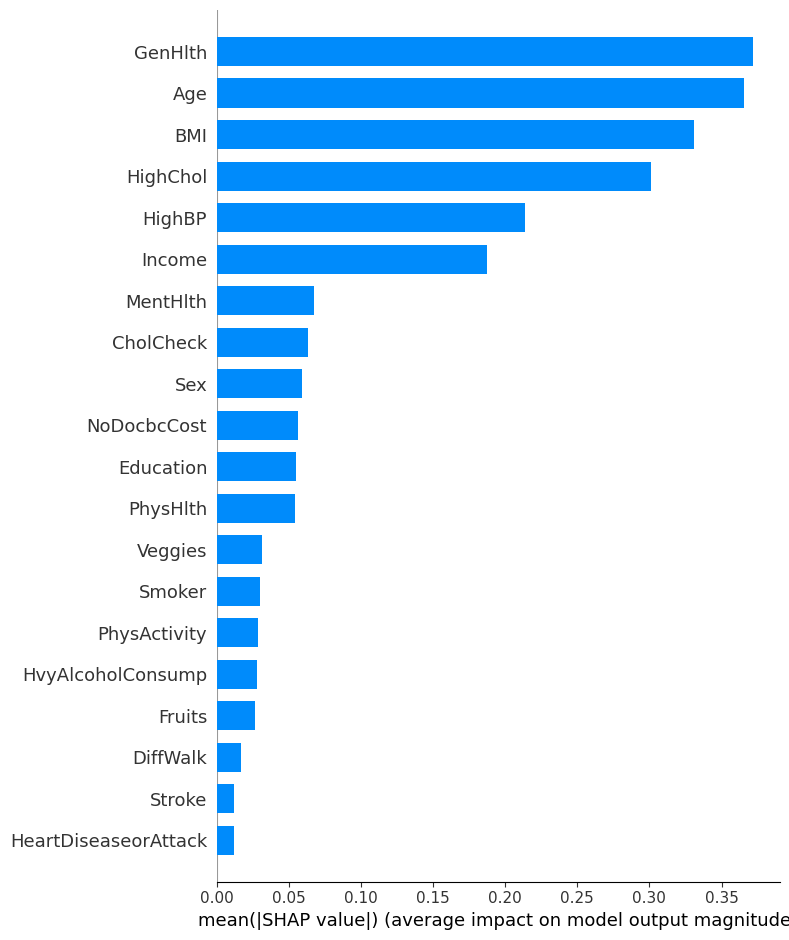


FEATURE IMPACT


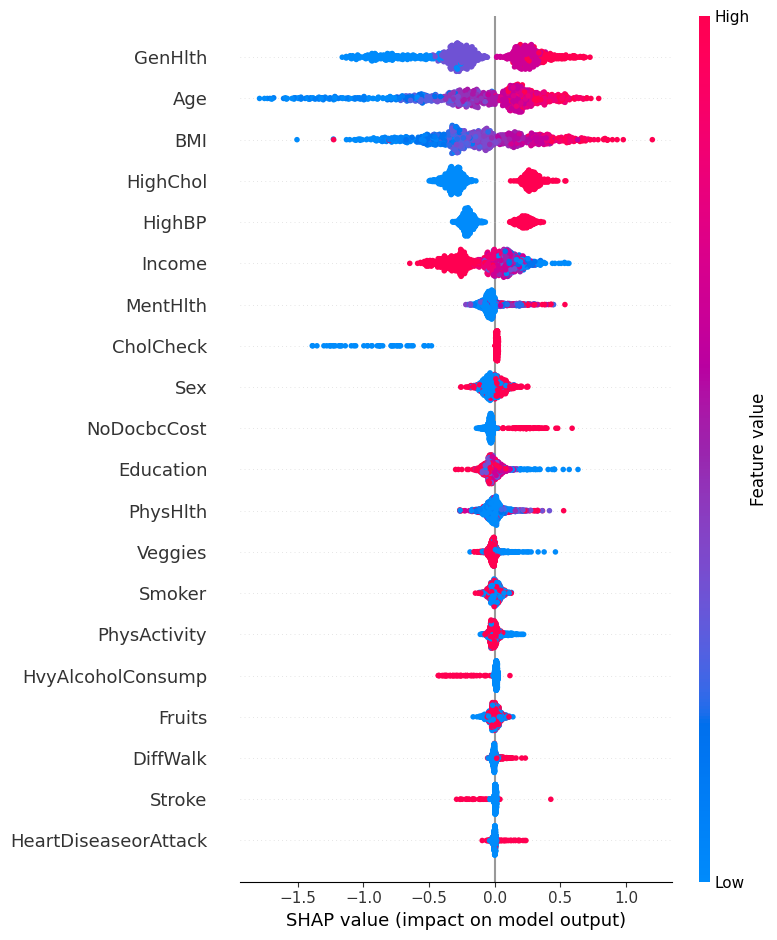

In [17]:

import os
import joblib
import numpy as np
import shap
import matplotlib.pyplot as plt

# 1. Save reconstructed models permanently
save_dir = "/content/drive/MyDrive/DiabeGuard_AI_Models"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(
    save_dir, "unweighted_pairwise_xgboost_models.joblib"
)

joblib.dump(unweighted_models, model_path)

print("Models saved:", model_path)

# 2. Rebuild Model A validation data
y_val_array = np.asarray(y_val)

val_mask = np.isin(y_val_array, [0, 1])

X_shap_val = X_val.iloc[np.where(val_mask)[0]]

# 3. Select Model A
model = unweighted_models[
    "Prediabetes vs No Diabetes"
]["model"]

# 4. Select a manageable sample
X_shap_sample = X_shap_val.sample(
    n=min(1000, len(X_shap_val)),
    random_state=42
)

print("\nSHAP validation samples:", len(X_shap_sample))
print("Number of features:", X_shap_sample.shape[1])

# 5. Calculate SHAP values
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(
    X_shap_sample
)

if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP values shape:", shap_values.shape)

# 6. Global feature importance
print("\nGLOBAL FEATURE IMPORTANCE")

shap.summary_plot(
    shap_values,
    X_shap_sample,
    plot_type="bar"
)

# 7. Feature impact
print("\nFEATURE IMPACT")

shap.summary_plot(
    shap_values,
    X_shap_sample
)



In [19]:

import pandas as pd
import numpy as np

# Calculate mean absolute SHAP values
importance = np.abs(shap_values).mean(axis=0)

shap_results = pd.DataFrame({
    "Feature": X_shap_sample.columns,
    "Mean_Absolute_SHAP": importance
})

shap_results = shap_results.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("TOP 21 SHAP FEATURES")
print("=" * 55)

print(shap_results.to_string(index=False))

print("\nTOP 10 FEATURES")
print(shap_results.head(10).to_string(index=False))


TOP 21 SHAP FEATURES
             Feature  Mean_Absolute_SHAP
             GenHlth            0.371974
                 Age            0.365264
                 BMI            0.330798
            HighChol            0.300882
              HighBP            0.213859
              Income            0.187355
            MentHlth            0.067214
           CholCheck            0.063117
                 Sex            0.058760
         NoDocbcCost            0.055928
           Education            0.054861
            PhysHlth            0.054319
             Veggies            0.031531
              Smoker            0.030195
        PhysActivity            0.028618
   HvyAlcoholConsump            0.027675
              Fruits            0.026583
            DiffWalk            0.016662
              Stroke            0.012024
HeartDiseaseorAttack            0.011496
       AnyHealthcare            0.007624

TOP 10 FEATURES
    Feature  Mean_Absolute_SHAP
    GenHlth            0.371

In [20]:

from sklearn.metrics import precision_recall_curve
import numpy as np

print("VALIDATION THRESHOLD OPTIMIZATION")
print("=" * 60)

best_thresholds = {}

for name, result in unweighted_models.items():
    y_true = np.asarray(result["y_true"])
    probabilities = np.asarray(result["probabilities"])

    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    # Calculate F1 for every available threshold
    f1_scores = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_scores)
    best_threshold = thresholds[best_index]

    predictions = (probabilities >= best_threshold).astype(int)

    best_thresholds[name] = float(best_threshold)

    print(f"\n{name}")
    print("-" * 45)
    print(f"Best threshold : {best_threshold:.4f}")
    print(f"Precision      : {precision[best_index]:.4f}")
    print(f"Recall         : {recall[best_index]:.4f}")
    print(f"F1 Score       : {f1_scores[best_index]:.4f}")
    print(f"Predicted cases: {predictions.sum()} / {len(predictions)}")

print("\nSELECTED THRESHOLDS")
print(best_thresholds)


VALIDATION THRESHOLD OPTIMIZATION

Prediabetes vs No Diabetes
---------------------------------------------
Best threshold : 0.0566
Precision      : 0.0682
Recall         : 0.2602
F1 Score       : 0.1081
Predicted cases: 2815 / 34954

Prediabetes vs Diabetes
---------------------------------------------
Best threshold : 0.1333
Precision      : 0.1746
Recall         : 0.4431
F1 Score       : 0.2505
Predicted cases: 1873 / 6314

SELECTED THRESHOLDS
{'Prediabetes vs No Diabetes': 0.05655236169695854, 'Prediabetes vs Diabetes': 0.13326625525951385}


In [21]:

import os
import joblib
import json
from datetime import datetime

save_dir = "/content/drive/MyDrive/DiabeGuard_AI_Models"
os.makedirs(save_dir, exist_ok=True)

# Deployment package
deployment_package = {
    "models": {
        name: result["model"]
        for name, result in unweighted_models.items()
    },
    "thresholds": best_thresholds,
    "feature_names": list(X_fit.columns),
    "model_type": "Pairwise XGBoost Binary Classification",
    "target_classes": {
        "0": "No Diabetes",
        "1": "Prediabetes",
        "2": "Diabetes"
    },
    "dataset": "CDC BRFSS 2015 Diabetes Health Indicators",
    "threshold_selection": "Validation set F1 optimization",
    "created_date": datetime.now().isoformat(),
    "disclaimer": "Research screening model; not a clinical diagnosis."
}

# Save complete deployment package
model_path = os.path.join(
    save_dir,
    "DiabeGuard_Final_Deployment_Package.joblib"
)

joblib.dump(deployment_package, model_path)

# Save thresholds separately for easy reference
threshold_path = os.path.join(save_dir, "selected_thresholds.json")

with open(threshold_path, "w") as f:
    json.dump(best_thresholds, f, indent=4)

print("MODEL PACKAGE SAVED SUCCESSFULLY")
print("=" * 50)
print("Model package:", model_path)
print("Threshold file:", threshold_path)
print("Models:", list(deployment_package["models"].keys()))
print("Features:", len(deployment_package["feature_names"]))
print("Thresholds:", deployment_package["thresholds"])


MODEL PACKAGE SAVED SUCCESSFULLY
Model package: /content/drive/MyDrive/DiabeGuard_AI_Models/DiabeGuard_Final_Deployment_Package.joblib
Threshold file: /content/drive/MyDrive/DiabeGuard_AI_Models/selected_thresholds.json
Models: ['Prediabetes vs No Diabetes', 'Prediabetes vs Diabetes']
Features: 21
Thresholds: {'Prediabetes vs No Diabetes': 0.05655236169695854, 'Prediabetes vs Diabetes': 0.13326625525951385}


In [22]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
import numpy as np

print("FINAL UNTOUCHED TEST-SET EVALUATION")
print("=" * 65)

test_results = {}

comparisons = {
    "Prediabetes vs No Diabetes": [0, 1],
    "Prediabetes vs Diabetes": [1, 2]
}

for name, classes in comparisons.items():

    # Select the relevant test samples
    mask = y_test.isin(classes)

    X_pair_test = X_test.loc[mask]
    y_pair_test = (y_test.loc[mask] == 1).astype(int)

    # Load model and previously selected threshold
    model = deployment_package["models"][name]
    threshold = deployment_package["thresholds"][name]

    # Predict probabilities
    probabilities = model.predict_proba(X_pair_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_pair_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_pair_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_pair_test, predictions, zero_division=0
    )
    pr_auc = average_precision_score(
        y_pair_test, probabilities
    )
    roc_auc = roc_auc_score(
        y_pair_test, probabilities
    )
    cm = confusion_matrix(y_pair_test, predictions)

    test_results[name] = {
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "pr_auc": pr_auc,
        "roc_auc": roc_auc,
        "confusion_matrix": cm.tolist()
    }

    print(f"\n{name}")
    print("-" * 50)
    print(f"Test samples       : {len(y_pair_test)}")
    print(f"Threshold          : {threshold:.4f}")
    print(f"Precision          : {precision:.4f}")
    print(f"Recall             : {recall:.4f}")
    print(f"F1 Score           : {f1:.4f}")
    print(f"PR-AUC             : {pr_auc:.4f}")
    print(f"ROC-AUC            : {roc_auc:.4f}")
    print(f"Predicted positives: {predictions.sum()}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_pair_test,
        predictions,
        target_names=["Negative", "Prediabetes"],
        zero_division=0
    ))

print("\nFINAL TEST EVALUATION COMPLETED")



FINAL UNTOUCHED TEST-SET EVALUATION

Prediabetes vs No Diabetes
--------------------------------------------------
Test samples       : 43758
Threshold          : 0.0566
Precision          : 0.0593
Recall             : 0.2383
F1 Score           : 0.0950
PR-AUC             : 0.0512
ROC-AUC            : 0.7495
Predicted positives: 3439

Confusion Matrix:
[[39667  3235]
 [  652   204]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.98      0.92      0.95     42902
 Prediabetes       0.06      0.24      0.09       856

    accuracy                           0.91     43758
   macro avg       0.52      0.58      0.52     43758
weighted avg       0.97      0.91      0.94     43758


Prediabetes vs Diabetes
--------------------------------------------------
Test samples       : 7844
Threshold          : 0.1333
Precision          : 0.1701
Recall             : 0.4591
F1 Score           : 0.2483
PR-AUC             : 0.1747
ROC-AUC            : 

In [23]:

import os
import joblib
import json

save_dir = "/content/drive/MyDrive/DiabeGuard_AI_Models"

# Attach final test evaluation to the package
deployment_package["test_evaluation"] = test_results

deployment_package["evaluation_status"] = (
    "Completed on untouched test set"
)

deployment_package["clinical_status"] = (
    "Research only - not validated for clinical diagnosis"
)

# Save updated package
model_path = os.path.join(
    save_dir,
    "DiabeGuard_Final_Deployment_Package.joblib"
)

joblib.dump(deployment_package, model_path)

# Save readable evaluation report
report_path = os.path.join(
    save_dir,
    "DiabeGuard_Final_Test_Report.json"
)

with open(report_path, "w") as f:
    json.dump(test_results, f, indent=4)

print("FINAL EVALUATION SAVED SUCCESSFULLY")
print("=" * 50)
print("Deployment package:", model_path)
print("Test report:", report_path)
print("Models:", len(deployment_package["models"]))
print("Features:", len(deployment_package["feature_names"]))
print("Evaluation status:", deployment_package["evaluation_status"])


FINAL EVALUATION SAVED SUCCESSFULLY
Deployment package: /content/drive/MyDrive/DiabeGuard_AI_Models/DiabeGuard_Final_Deployment_Package.joblib
Test report: /content/drive/MyDrive/DiabeGuard_AI_Models/DiabeGuard_Final_Test_Report.json
Models: 2
Features: 21
Evaluation status: Completed on untouched test set


In [24]:

from google.colab import files

model_path = "/content/drive/MyDrive/DiabeGuard_AI_Models/DiabeGuard_Final_Deployment_Package.joblib"

files.download(model_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
! pip install --upgrade --quiet accelerate bitsandbytes transformers

## Load model from Hugging Face Hub

In [3]:
from transformers import BitsAndBytesConfig
import torch

model_variant = "medgemma-1.5-4b-it"  # @param ["medgemma-1.5-4b-it", "medgemma-4b-it", "medgemma-27b-it", "medgemma-27b-text-it"]
model_id = f"google/{model_variant}"

# @markdown ---
# @markdown To reduce memory usage, [quantize](https://huggingface.co/docs/transformers/en/quantization/bitsandbytes) the model in 4-bit. **Note:** 4-bit quantization is required to run MedGemma 27B on an A100 GPU in Google Colab. The performance of quantized versions has not been evaluated.
use_quantization = True  # @param {type: "boolean"}

# @markdown ---
# @markdown MedGemma 1.5 4B and MedGemma 27B variants support thinking. If enabled, a system instruction will be added to prompt the model to output its reasoning between two special tokens `<unused94>` and `<unused95>` followed by the final response. **Note:** This notebook shows how to enable thinking for any multimodal or text-only task but it may not benefit some use cases. Thinking may potentially improve results on challenging text-only tasks at the cost of generating more tokens. Thoroughly validate the model's performance and assess the inference time and cost when enabling thinking.
is_thinking = False  # @param {type: "boolean"}
THINKING_VARIANTS = [
    "medgemma-1.5-4b-it",
    "medgemma-27b-it",
    "medgemma-27b-text-it",
]
if is_thinking and model_variant not in THINKING_VARIANTS:
    is_thinking = False
    print(
        "Note: Thinking is enabled for a non-thinking variant. Setting "
        "`is_thinking` to `False`."
    )

# If running a 27B variant in Google Colab, check if the runtime satisfies
# memory requirements
if "27b" in model_variant and google_colab:
    if not ("A100" in torch.cuda.get_device_name(0) and use_quantization):
        raise ValueError(
            "Runtime has insufficient memory to run a 27B variant. "
            "Please select an A100 GPU and use 4-bit quantization."
        )

model_kwargs = dict(
    dtype=torch.bfloat16,
    device_map="auto",
)

if use_quantization:
    model_kwargs["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True)

The following sections contain standalone examples demonstrating how to use the model both directly and with the [`pipeline`](https://huggingface.co/docs/transformers/en/main_classes/pipelines) API. The `pipeline` API provides a simple way to use the model for inference while abstracting away complex details,  while directly using the model gives you complete control over the inference process, including preprocessing and postprocessing. In practice, you should select the method that is best suited for your use case.

Here, you will load the model directly and with the `pipeline` API for use in the next sections. Note that the multimodal variants and the 27B text-only variant are loaded with their respective tasks and classes.

**Load model with the `pipeline` API**

In [4]:
from transformers import pipeline

if "text" in model_variant:
    pipe = pipeline("text-generation", model=model_id, model_kwargs=model_kwargs)
else:
    pipe = pipeline("image-text-to-text", model=model_id, model_kwargs=model_kwargs)

config.json:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

**Load model directly**

In [5]:
if "text" in model_variant:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    model = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)
    tokenizer = AutoTokenizer.from_pretrained(model_id)
else:
    from transformers import AutoModelForImageTextToText, AutoProcessor
    model = AutoModelForImageTextToText.from_pretrained(model_id, **model_kwargs)
    processor = AutoProcessor.from_pretrained(model_id)

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

## Run inference on images and text

This section demonstrates running inference on image-based tasks using multimodal variants.

**Note:** Proceed to [Run inference on text only](#scrollTo=tcyXG4lTpY4X) if you have selected the 27B text-only variant.

In [6]:
if "text" in model_variant:
    raise ValueError(
        "You are using a text-only variant which does not support multimodal "
        "inputs. Please proceed to the 'Run inference on text only' section."
    )

**Specify image and text inputs**

In [7]:
import os
from PIL import Image
from IPython.display import Image as IPImage, display, Markdown

prompt = "Describe this X-ray"  # @param {type: "string"}

# Image attribution: Stillwaterising, CC0, via Wikimedia Commons
image_url = "https://upload.wikimedia.org/wikipedia/commons/c/c8/Chest_Xray_PA_3-8-2010.png"  # @param {type: "string"}
! wget -nc -q {image_url}
image_filename = os.path.basename(image_url)
image = Image.open(image_filename)

FileNotFoundError: [Errno 2] No such file or directory: 'Chest_Xray_PA_3-8-2010.png'

**Format conversation**

In [ ]:
role_instruction = "You are an expert radiologist."
if is_thinking:
    system_instruction = f"SYSTEM INSTRUCTION: think silently if needed. {role_instruction}"
    max_new_tokens = 1300
else:
    system_instruction = role_instruction
    max_new_tokens = 300

messages = [
    {
        "role": "system",
        "content": [{"type": "text", "text": system_instruction}]
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": prompt},
            {"type": "image", "image": image}
        ]
    }
]

**Run model with the `pipeline` API**

In [ ]:
output = pipe(text=messages, max_new_tokens=max_new_tokens, do_sample=False)
response = output[0]["generated_text"][-1]["content"]

display(Markdown(f"---\n\n**[ User ]**\n\n{prompt}"))
display(IPImage(filename=image_filename, height=300))
if is_thinking:
    thought, response = response.split("<unused95>")
    thought = thought.replace("<unused94>thought\n", "")
    display(Markdown(f"---\n\n**[ MedGemma thinking trace ]**\n\n{thought}"))
display(Markdown(f"---\n\n**[ MedGemma ]**\n\n{response}\n\n---"))

**Run the model directly**

In [ ]:
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device, dtype=torch.bfloat16)

input_len = inputs["input_ids"].shape[-1]

with torch.inference_mode():
    generation = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    generation = generation[0][input_len:]

response = processor.decode(generation, skip_special_tokens=True)

display(Markdown(f"---\n\n**[ User ]**\n\n{prompt}"))
display(IPImage(filename=image_filename, height=300))
if is_thinking:
    thought, response = response.split("<unused95>")
    thought = thought.replace("<unused94>thought\n", "")
    display(Markdown(f"---\n\n**[ MedGemma thinking trace ]**\n\n{thought}"))
display(Markdown(f"---\n\n**[ MedGemma ]**\n\n{response}\n\n---"))

## Run inference on text only

This section demonstrates running inference on text-based tasks.

**Specify text prompt and format conversation**

In [ ]:
from IPython.display import Markdown

prompt = "How do you differentiate bacterial from viral pneumonia?"  # @param {type: "string"}

role_instruction = "You are a helpful medical assistant."
if is_thinking:
    system_instruction = f"SYSTEM INSTRUCTION: think silently if needed. {role_instruction}"
    max_new_tokens = 1500
else:
    system_instruction = role_instruction
    max_new_tokens = 500

messages = [
    {
        "role": "system",
        "content": [{"type": "text", "text": system_instruction}]
    },
    {
        "role": "user",
        "content": [{"type": "text", "text": prompt}]
    }
]

**Run model with the `pipeline` API**

In [ ]:
output = pipe(messages, max_new_tokens=max_new_tokens, do_sample=False)
response = output[0]["generated_text"][-1]["content"]

display(Markdown(f"---\n\n**[ User ]**\n\n{prompt}\n\n---"))
if is_thinking:
    thought, response = response.split("<unused95>")
    thought = thought.replace("<unused94>thought\n", "")
    display(Markdown(f"**[ MedGemma thinking trace ]**\n\n{thought}\n\n---"))
display(Markdown(f"**[ MedGemma ]**\n\n{response}\n\n---"))

**Run the model directly**

In [ ]:
processor_or_tokenizer = tokenizer if "text" in model_variant else processor

inputs = processor_or_tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

input_len = inputs["input_ids"].shape[-1]

with torch.inference_mode():
    generation = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    generation = generation[0][input_len:]

response = processor_or_tokenizer.decode(generation, skip_special_tokens=True)

display(Markdown(f"---\n\n**[ User ]**\n\n{prompt}\n\n---"))
if is_thinking:
    thought, response = response.split("<unused95>")
    thought = thought.replace("<unused94>thought\n", "")
    display(Markdown(f"**[ MedGemma thinking trace ]**\n\n{thought}\n\n---"))
display(Markdown(f"**[ MedGemma ]**\n\n{response}\n\n---"))

## Next steps

Explore the other [notebooks](https://github.com/google-health/medgemma/blob/main/notebooks) to learn what else you can do with the model.